# Escaped asteroid tracking

The escaped asteroids have been identified in escaped asteroids h5 file.

Now I need to read the relevant pval_?????.h5 log and track where the asteroid wandered.


In [2]:
import datetime as datetime

import pandas as pd
import numpy as np
import h5py as h5

import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import cm

xlabel_time = 'Years after start of simulation [$10^8 ~ yr$]'

In [3]:
# Read the escaped asteroids file
ea_mmc3 = pd.read_hdf('../../asteroid_data/mc_pm6_3/escaped_asteroids.h5')

In [4]:
ea_mmc3

,ast_name,vectors,sim_no,particle_number,parameter,parameter_value,integration_year
0,16794,XcpYcmZcpVXcpVYcmVZcp,00148,8,6,4.118940,6.208498e+08
1,499395,XcpYcmZcpVXcpVYcmVZcp,00148,9,6,0.000000,6.214782e+08
2,2002 FL44,XcpYcmZcpVXcpVYcmVZcp,00148,10,6,7.460342,5.435590e+08
3,16794,XcpYcmZcpVXcpVYcmVZcp,00148,8,7,0.429269,5.957146e+08
4,2002 FL44,XcpYcmZcpVXcpVYcmVZcp,00148,10,7,0.448423,4.964305e+08
...,...,...,...,...,...,...,...
17903,2010 MD2,XcpYcmZcmVXcmVYcmVZcp,13095,10,6,0.000000,1.320866e+09
17904,2010 MD2,XcpYcmZcmVXcmVYcmVZcp,13095,10,7,0.342173,7.609786e+08
17905,2010 MD2,XcpYcmZcmVXcpVYcpVZcm,13090,10,6,6.635770,2.012084e+09
17906,2010 MD2,XcpYcmZcmVXcpVYcpVZcm,13090,10,7,0.385064,1.554623e+09


In [5]:
ea_grouped1 = ea_mmc3[ea_mmc3.parameter==6][['ast_name','vectors']].groupby('ast_name').size()

asteroid_track_names = ea_grouped1[ea_grouped1 > (65*0.75)].index

In [6]:
asteroid_track_names

Index(['2002 FL44', '2002 NO62', '2003 FY123', '2003 HJ19', '2004 RG295',
       '2004 UJ9', '2005 BQ54', '2005 TJ65', '2005 UM306', '2005 VC153',
       '2005 YY288', '2006 GO59', '2006 SD297', '2006 SU386', '2006 TJ144',
       '2006 UG302', '2006 UJ153', '2006 UQ383', '2006 UZ380', '2006 VU180',
       '2006 VY37', '2007 AP37', '2007 BG119', '2007 RS254', '2007 TV494',
       '2008 CW212', '2008 RY179', '2010 TE73', '2010 VE256', '2010 VJ67',
       '2011 AQ78', '2011 EJ14', '2011 HL50', '2011 ON68', '2011 QK64',
       '2011 SR330', '2011 UR456', '2011 UX486', '2012 AL36', '2012 BE119',
       '2012 DV124', '2012 FP28', '2012 PK61', '2012 QD29', '2012 UG127',
       '2012 UL227', '2012 UR215', '2012 UT240', '2012 XF94', '2012 XW89',
       '2013 BH34', '2013 CE106', '2013 CP257', '2014 OJ68', '2014 OK286',
       '2014 QZ266', '2016 BG27', '2016 PG131', '2017 HL46', '2017 KV6',
       '2018 VX15', '2018 WO1', '235306', '507863', '533569'],
      dtype='object', name='ast_name')

In [7]:
escaped_ast_sim = ea_mmc3[ea_mmc3.ast_name.isin(asteroid_track_names)][['ast_name','sim_no','particle_number']]
escaped_ast_sim = escaped_ast_sim.drop_duplicates()

In [8]:
escaped_ast_sim

,ast_name,sim_no,particle_number
2,2002 FL44,00148,10
7,2002 FL44,00174,10
12,2002 FL44,00191,10
18,2002 FL44,00167,10
28,2002 FL44,00190,10
...,...,...,...
17885,2008 RY179,08499,10
17889,2008 RY179,08514,10
17891,2008 RY179,08512,10
17894,2008 RY179,08502,10


2002 FL44


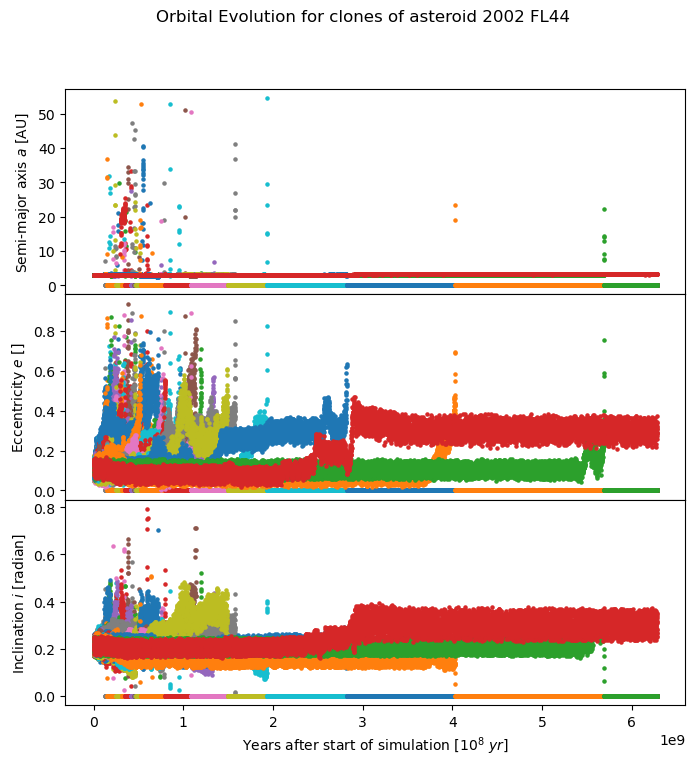

2002 NO62


KeyboardInterrupt: 

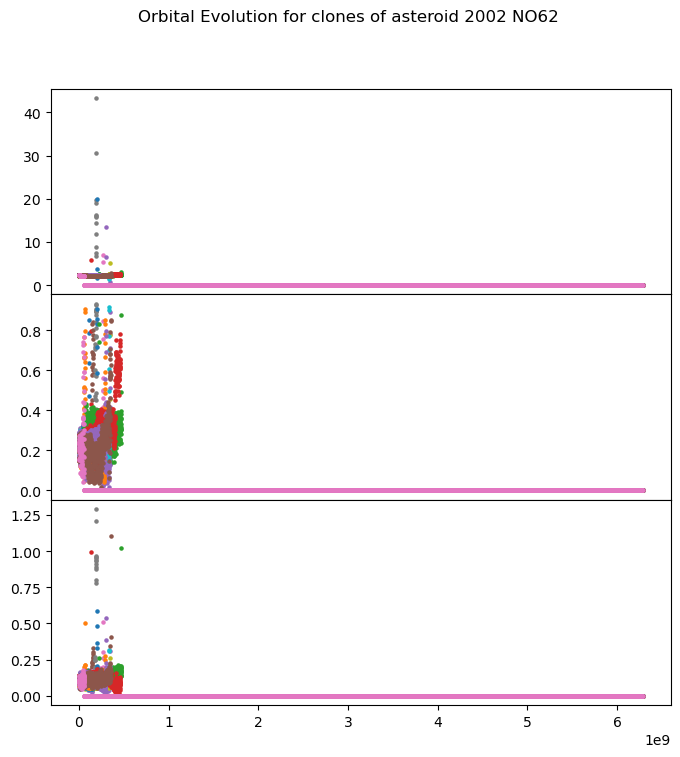

In [10]:
for ast_name in asteroid_track_names:
    ast_array = escaped_ast_sim.loc[escaped_ast_sim.ast_name==ast_name].values
    print(ast_name)
    int_values = None
    plot_vals = np.zeros([10000,len(ast_array), 11])
    
    # plt.style.use('fivethirtyeight')
    fig = plt.figure(figsize=(8, 8))
    fig.suptitle(f'Orbital Evolution for clones of asteroid {ast_name} ')
    gs = fig.add_gridspec(3, hspace=0)
    (ax1, ax2, ax3) = gs.subplots(sharex=True)

    for p_no, (_, sim_file, particle_no) in enumerate(ast_array):
        with h5.File(f"../../asteroid_data/mc_pm6_3/fawkes_pvals/pvals_{sim_file:05}.h5", 'r') as sim_log:
            # Unpack the H5
            # Store the first array of time steps (they're duplicated across H5's)
            if int_values is None:
                int_values = sim_log['integration_time_values'][()]
            #Copy the values for the particle
            part_values = sim_log['particle_values'][()]
            #print(1,part_values[:,particle_no-8,:].shape)
            #print(2,plot_vals[:,p_no,:].shape)
            plot_vals[:,p_no,:] = part_values[:,particle_no-8,:]
            ax1.scatter(int_values[:], plot_vals[:,p_no, 6], s=5, marker='o')
            ax2.scatter(int_values[:], plot_vals[:,p_no, 7], s=5, marker='o')
            ax3.scatter(int_values[:], plot_vals[:,p_no, 8], s=5, marker='o')

    plt.xlabel(xlabel_time)
    ax1.set_ylabel("Semi-major axis $a$ [AU]")
    ax1.label_outer()
    ax2.set_ylabel("Eccentricity $e$ []")
    ax2.label_outer()
    ax3.set_ylabel("Inclination $i$ [radian]")
    plt.savefig(f"../../asteroid_data/mc_pm6_3/plots/orb_evol_{ast_name.replace(' ','_')}.png", dpi='300')
    plt.show()
    


In [ ]:
test_log = h5.File("../../asteroid_data/mc_pm6_3/fawkes_pvals/pvals_00148.h5", 'r')

int_values = test_log['integration_time_values'][()]
int_values = int_values/(2*np.pi)

part_values = test_log['particle_values'][()]
sim_energy_values = test_log['sim_energy_values'][()]
# Extract the index of the integration time
time_index = np.argwhere(int_values <= int_year)[-100]

print(int_values.shape, part_values.shape, sim_energy_values.shape)
    
print(np.mean(sim_energy_values))
test_log.close()

In [ ]:
escaped_ast_sim.loc[escaped_ast_sim.ast_name=='2002 FL44'].values

# This is to create a list of pval files to download
"""
with open("../../asteroid_data/mc_pm6_3/required_pvals", "w") as outfile:
    outfile.write("\n".join(sim_files))
"""

